# Imports

In [6]:
from diffrax import diffeqsolve, ODETerm, SaveAt, Tsit5
import jax, jax.numpy as jnp
import matplotlib, matplotlib.pyplot as plt
import numpy as np
import scienceplots

from models import Parameters, SIS, SIR

plt.style.use([
    'science',
    'no-latex'
    ])
plt.rcParams['text.latex.preamble'] = r'\usepackage{newtxmath, newtxtext}'
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.Set1.colors)

FIGSIZE = (2.5, 2.5*3/4)

# set every font size to 10pt
# plt.rcParams.update({'font.size': 8})

# SIS Model

{'max_steps': 4096, 'num_accepted_steps': Array(160, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(160, dtype=int64, weak_type=True)}
{'max_steps': 4096, 'num_accepted_steps': Array(80, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(80, dtype=int64, weak_type=True)}
Maximum relative error: 2.6171784136378663e-10


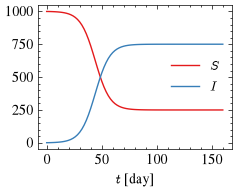

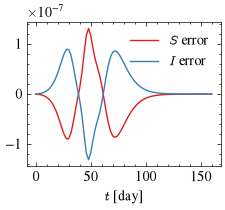

In [7]:
p = Parameters(alpha=0.05, beta=0.2)
solver = Tsit5()
y0 = np.array([[1000, 1]])

t0 = 0.0
t1 = 160.0
dt_fine = 1.0
dt_coarse = 2.0
saveat = SaveAt(ts=jnp.arange(t0, t1+dt_coarse, dt_coarse))

fine_sol = diffeqsolve(SIS, solver, t0=t0, t1=t1, dt0=dt_fine, y0=y0, args=p, saveat=saveat)
coarse_sol = diffeqsolve(SIS, solver, t0=t0, t1=t1, dt0=dt_coarse, y0=y0, args=p, saveat=saveat)
print(fine_sol.stats)
print(coarse_sol.stats)

ts = fine_sol.ts
S, I = fine_sol.ys.T
S_error, I_error = ((fine_sol.ys - coarse_sol.ys) / (2**solver.order(SIS) - 1)).T

plt.figure(figsize=FIGSIZE)
plt.plot(ts, S.flatten(), label=r"$S$")
plt.plot(ts, I.flatten(), label=r"$I$")
plt.xlabel(r"$t$ [day]")
plt.legend()
plt.savefig("../figures/SIS.pdf")

plt.figure(figsize=FIGSIZE)
plt.plot(ts, S_error.flatten(), label=r"$S$ error")
plt.plot(ts, I_error.flatten(), label=r"$I$ error")
plt.xlabel(r"$t$ [day]")
plt.legend()
plt.savefig("../figures/SIS_error.pdf")

# compute norm of error/norm of solution
error_norm = jnp.linalg.norm(jnp.vstack([S_error, I_error]), axis=0, ord=2)
ys_norm = jnp.linalg.norm(jnp.vstack([S, I]), axis=0, ord=2)
print(f"Maximum relative error: {jnp.max(error_norm/ys_norm)}")

# SIR Model

{'max_steps': 4096, 'num_accepted_steps': Array(100, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(100, dtype=int64, weak_type=True)}
{'max_steps': 4096, 'num_accepted_steps': Array(50, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(50, dtype=int64, weak_type=True)}
Maximum relative error: 1.3676308551541768e-07


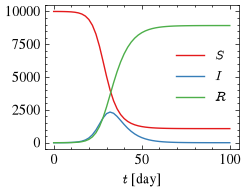

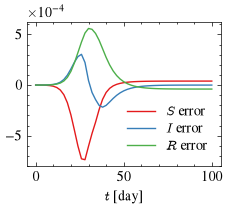

In [8]:
p = Parameters(alpha=0.2, beta=0.5, gamma=0.0)
solver = Tsit5()
y0 = np.array([[10000, 1, 0]])

t0 = 0.0
t1 = 100.0
dt_fine = 1.0
dt_coarse = 2.0
saveat = SaveAt(ts=jnp.arange(t0, t1+dt_coarse, dt_coarse))

fine_sol = diffeqsolve(SIR, solver, t0=t0, t1=t1, dt0=dt_fine, y0=y0, args=p, saveat=saveat)
coarse_sol = diffeqsolve(SIR, solver, t0=t0, t1=t1, dt0=dt_coarse, y0=y0, args=p, saveat=saveat)
print(fine_sol.stats)
print(coarse_sol.stats)

ts = fine_sol.ts
S, I, R = fine_sol.ys.T
S_error, I_error, R_error = ((fine_sol.ys - coarse_sol.ys) / (2**solver.order(SIR) - 1)).T

plt.figure(figsize=FIGSIZE)
plt.plot(ts, S.flatten(), label=r"$S$")
plt.plot(ts, I.flatten(), label=r"$I$")
plt.plot(ts, R.flatten(), label=r"$R$")
plt.xlabel(r"$t$ [day]")
plt.legend()
plt.savefig("../figures/SIR.pdf")

plt.figure(figsize=FIGSIZE)
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.plot(ts, S_error.flatten(), label=r"$S$ error")
plt.plot(ts, I_error.flatten(), label=r"$I$ error")
plt.plot(ts, R_error.flatten(), label=r"$R$ error")
plt.xlabel(r"$t$ [day]")
plt.legend(loc="lower right", labelspacing=0.25)
plt.savefig("../figures/SIR_error.pdf")

# compute norm of error/norm of solution
error_norm = jnp.linalg.norm(jnp.vstack([S_error, I_error, R_error]), axis=0, ord=2)
ys_norm = jnp.linalg.norm(jnp.vstack([S, I, R]), axis=0, ord=2)
print(f"Maximum relative error: {jnp.max(error_norm/ys_norm)}")

# SIR Model with Travel

In [9]:
N0 = 1e4
N1 = 1e4
W = np.array([[0.0, 1e-3], [1e-3, 0.0]])
p = Parameters(alpha=0.2, beta=0.5, gamma=5e-3, W=W)
solver = Tsit5()
y0 = np.array([[N0 - 1, N1], [1, 0,], [0, 0]]).flatten()

{'max_steps': 4096, 'num_accepted_steps': Array(100, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(100, dtype=int64, weak_type=True)}
{'max_steps': 4096, 'num_accepted_steps': Array(50, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(50, dtype=int64, weak_type=True)}


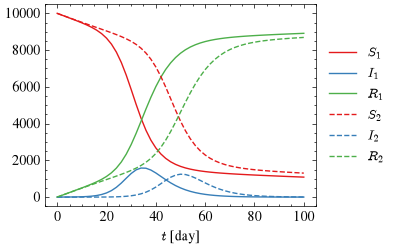

In [12]:
t0 = 0.0
t1 = 100.0
dt_fine = 1.0
dt_coarse = 2.0
saveat = SaveAt(ts=jnp.arange(t0, t1+dt_coarse, dt_coarse))

fine_sol = diffeqsolve(SIR, solver, t0=t0, t1=t1, dt0=dt_fine, y0=y0, args=p, saveat=saveat)
coarse_sol = diffeqsolve(SIR, solver, t0=t0, t1=t1, dt0=dt_coarse, y0=y0, args=p, saveat=saveat)
print(fine_sol.stats)
print(coarse_sol.stats)

ts = fine_sol.ts
ys_fine = fine_sol.ys.reshape((-1, 3, p.n_cities))
ys_coarse = coarse_sol.ys.reshape((-1, 3, p.n_cities))

# plot ys_fine and ys_coarse for each city
plt.figure()#figsize=FIGSIZE)
S0_line = plt.plot(ts, ys_fine[:, 0, 0].flatten(), label=r"$S_1$")
I0_line = plt.plot(ts, ys_fine[:, 1, 0].flatten(), label=r"$I_1$")
R0_line = plt.plot(ts, ys_fine[:, 2, 0].flatten(), label=r"$R_1$")

S1_line = plt.plot(ts, ys_fine[:, 0, 1].flatten(), label=r"$S_2$", color=S0_line[0].get_color(), linestyle="--")
I1_line = plt.plot(ts, ys_fine[:, 1, 1].flatten(), label=r"$I_2$", color=I0_line[0].get_color(), linestyle="--")
R1_line = plt.plot(ts, ys_fine[:, 2, 1].flatten(), label=r"$R_2$", color=R0_line[0].get_color(), linestyle="--")
plt.xlabel(r"$t$ [day]")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.savefig("../figures/SIR_coupled.pdf")